# `vkcolorcet` Demo — Perceptually Uniform Vulkan GPU Colormaps

Drop-in `colorcet`-style colormaps (`fire`, `bmy`, `bgy`, `kbc`, `viridis`, `inferno`, `plasma`, `magma`, `turbo`, `coolwarm`, `rainbow`, `glasbey`, ...) executed directly inside `vkshader`'s zero-copy Vulkan SPIR-V LUT shader!

In [1]:
import sys
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import vkcolorcet as cc
cc.swatches()

fire,
bmy,
bgy,
bgyw,
kbc,
kb,
kg,
kr,
bmw,
viridis,
inferno,


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


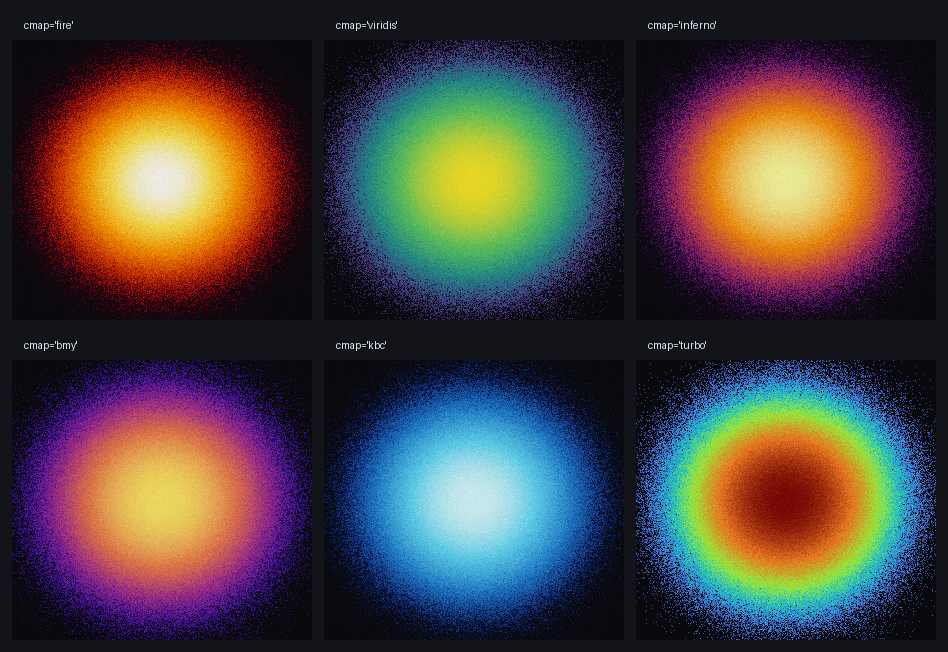

In [2]:
import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkholoviews as hv
import vkplot.vkpandas  # noqa: F401

# Render 2M GPU points with 6 different vkcolorcet colormaps
rng = np.random.default_rng(77)
n = 2_000_000
df = vpd.DataFrame({
    "x": vnp.array(rng.normal(0.0, 1.0, size=n).astype(np.float32)),
    "y": vnp.array(rng.normal(0.0, 1.0, size=n).astype(np.float32)),
})

cmaps = ["fire", "viridis", "inferno", "bmy", "kbc", "turbo"]
plots = [
    df.vkplot.points("x", "y", cmap=cm, width=300, height=280, xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), title=f"cmap={cm!r}")
    for cm in cmaps
]
hv.Layout(plots).cols(3)